# N=3 retuning and final-model preparation

N=3 is the primary monitoring budget; N=5 is secondary. This choice followed earlier development analysis and is documented as such. The study retunes book-only logistic and random-forest occurrence classifiers, and the metadata-inclusive two-stage TabM value model. Fixed classical controls remain in the comparison.

**This notebook does not open the final test.** Development-fold evaluation and full-development final refits are separate. Read [the preparation report](../docs/reports/final_preparation.md).

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
import torch
from threadpoolctl import threadpool_limits
from IPython.display import display, Image
from src.models.final_preparation import prepare, verify, predict_final
from src.simulator.final_preparation import replay
from src.reporting.final_preparation import build_report, verify_replay, verify_analysis, LABELS

torch.set_num_threads(4)
MODELS = ROOT / 'results/final_preparation'
REPLAY = ROOT / 'results/final_preparation_replay'
RUN_PREPARATION = False
RUN_REPLAY = False
REBUILD_REPORT = False
# Use fresh paths before enabling preparation or replay.
with threadpool_limits(limits=4):
    if RUN_PREPARATION:
        prepare(MODELS, device='cuda' if torch.cuda.is_available() else 'cpu')
    if RUN_REPLAY:
        replay(REPLAY, MODELS)
    if REBUILD_REPORT:
        build_report(MODELS, REPLAY)
    design = verify(MODELS)
    verify_replay(REPLAY, MODELS)
    verify_analysis(MODELS, REPLAY)
print('Verified N=3 tuning, saved models, development-only replay and closed final test.')

Verified N=3 tuning, saved models, development-only replay and closed final test.


## Two distinct fitting stages

**Development comparison:** each of three expanding folds tunes eight settings on two earlier chronological validation blocks. Logistic and forest select by positive-hour recall@3; two-stage TabM selects by captured peak quote value@3. TabM's two networks choose epochs by inner log loss/MSE and refit for the median selected epoch count, using three seeds. No P&L enters selection.

**Final preparation:** a fourth origin at 8 January 2026 selects settings afresh using two development-only validation blocks. Final models then fit all known earlier label windows ending strictly before that boundary. These final models do not generate the development performance tables below.

Book-only inputs have 33 raw columns. TabM adds event type, topic and age for 36 columns. Final choices preserve both fixed and tuned classical models; the test will not silently discard whichever one performs worse.

In [2]:
selected = pd.read_csv(MODELS / 'selected_parameters.csv')
display(selected.rename(columns={'classifier':'gate_epochs','amount':'amount_epochs'}))
display(pd.read_csv(MODELS / 'analysis/inner_budget_choices.csv'))
print('N=5 choices above are reconstructed from the same saved inner scores; they do not trigger extra fits.')

,origin,method,candidate,top_n,params,gate_epochs,amount_epochs
0,nov_early,logistic,6,3,"{""C"": 0.1, ""class_weight"": null, ""penalty"": ""l...",NaN,NaN
1,nov_early,random_forest,4,3,"{""max_depth"": 12, ""max_features"": 0.5, ""min_sa...",NaN,NaN
2,nov_early,tabm_two_stage,4,3,"{""d_block"": 128, ""dropout"": 0.1, ""lr"": 0.001, ...",45.0,8.0
3,nov_late,logistic,4,3,"{""C"": 0.1, ""class_weight"": ""balanced"", ""penalt...",NaN,NaN
4,nov_late,random_forest,0,3,"{""max_depth"": 10, ""max_features"": ""sqrt"", ""min...",NaN,NaN
5,nov_late,tabm_two_stage,7,3,"{""d_block"": 64, ""dropout"": 0.2, ""lr"": 0.002, ""...",16.0,19.0
6,dec_late,logistic,6,3,"{""C"": 0.1, ""class_weight"": null, ""penalty"": ""l...",NaN,NaN
7,dec_late,random_forest,0,3,"{""max_depth"": 10, ""max_features"": ""sqrt"", ""min...",NaN,NaN
8,dec_late,tabm_two_stage,7,3,"{""d_block"": 64, ""dropout"": 0.2, ""lr"": 0.002, ""...",26.0,38.0
9,final_refit,logistic,6,3,"{""C"": 0.1, ""class_weight"": null, ""penalty"": ""l...",NaN,NaN


,origin,method,n3_candidate,n5_candidate,changed
0,dec_late,logistic,6,4,True
1,dec_late,random_forest,0,1,True
2,dec_late,tabm_two_stage,7,7,False
3,final_refit,logistic,6,1,True
4,final_refit,random_forest,0,5,True
5,final_refit,tabm_two_stage,1,1,False
6,nov_early,logistic,6,6,False
7,nov_early,random_forest,4,4,False
8,nov_early,tabm_two_stage,4,7,True
9,nov_late,logistic,4,1,True


N=5 choices above are reconstructed from the same saved inner scores; they do not trigger extra fits.


## Development opportunity capture

The quoted-value target is the largest qualifying displayed basket margin within an hour, not total collectible hourly profit. Unknown labels remain eligible for ranking but do not enter fitting or become zero targets. N=5 results use the same N=3-tuned predictions.

The fixed book logistic model captures the most positive hours at N=3 (342/385); the retuned two-stage TabM captures 99.21% of peak quoted value. Retuning the classical models underperforms their fixed controls, particularly in the first fold. These controls remain in the comparison. Neither metric alone identifies a final winning strategy.

In [3]:
metrics = pd.read_csv(MODELS / 'metrics.csv')
headline = metrics.loc[metrics.fold.eq('all')]
columns = ['model','top_n','captured_positive_windows','positive_windows','recall','peak_value_recall','new_without_scan_recall','selected_unknown']
for scope in ('all_events','exclude_december_fed'):
    print(scope)
    display(headline.loc[headline.scope.eq(scope), columns].sort_values(['top_n','model']).round(4))
display(pd.read_csv(MODELS / 'analysis/paired_value_intervals.csv').round(4))

all_events


,model,top_n,captured_positive_windows,positive_windows,recall,peak_value_recall,new_without_scan_recall,selected_unknown
0,fixed_book_logistic,3,342,385,0.8883,0.9807,0.8283,117
8,fixed_book_random_forest,3,339,385,0.8805,0.9845,0.8069,496
16,n3_book_logistic,3,279,385,0.7247,0.5635,0.5579,929
24,n3_book_random_forest,3,330,385,0.8571,0.7850,0.7682,756
32,n3_tabm_two_stage,3,334,385,0.8675,0.9921,0.7983,237
40,quoted_gap_rule,3,273,385,0.7091,0.6008,0.5193,1316
48,tabm_tuned_two_stage,3,336,385,0.8727,0.9921,0.8069,176
1,fixed_book_logistic,5,376,385,0.9766,0.9943,0.9614,461
9,fixed_book_random_forest,5,367,385,0.9532,0.9986,0.9227,1272
17,n3_book_logistic,5,361,385,0.9377,0.9928,0.8970,1060


exclude_december_fed


,model,top_n,captured_positive_windows,positive_windows,recall,peak_value_recall,new_without_scan_recall,selected_unknown
56,fixed_book_logistic,3,265,285,0.9298,0.9642,0.8938,168
64,fixed_book_random_forest,3,252,285,0.8842,0.9757,0.8000,845
72,n3_book_logistic,3,233,285,0.8175,0.9172,0.6875,944
80,n3_book_random_forest,3,250,285,0.8772,0.9539,0.7875,954
88,n3_tabm_two_stage,3,250,285,0.8772,0.9773,0.8062,443
96,quoted_gap_rule,3,221,285,0.7754,0.8394,0.6000,1344
104,tabm_tuned_two_stage,3,251,285,0.8807,0.9770,0.8125,333
57,fixed_book_logistic,5,283,285,0.9930,0.9999,0.9875,860
65,fixed_book_random_forest,5,277,285,0.9719,0.9976,0.9500,1560
73,n3_book_logistic,5,274,285,0.9614,0.9667,0.9312,1102


,model,top_n,difference,lower95,upper95,families
0,fixed_book_logistic,3,0.3799,0.0702,0.4024,9
1,fixed_book_random_forest,3,0.3837,0.1645,0.3961,9
2,n3_book_logistic,3,-0.0373,-0.0461,0.1225,9
3,n3_book_random_forest,3,0.1842,0.0391,0.2260,9
4,n3_tabm_two_stage,3,0.3913,0.0150,0.4005,9
5,quoted_gap_rule,3,0.0000,0.0000,0.0000,9
6,tabm_tuned_two_stage,3,0.3913,0.0151,0.4005,9
7,fixed_book_logistic,5,0.0154,-0.0001,0.1667,9
8,fixed_book_random_forest,5,0.0196,0.0000,0.2447,9
9,n3_book_logistic,5,0.0139,-0.0089,0.1608,9


## Development economics

Only the earlier-trained outer-fold predictions are replayed. The primary scenario is **100 ms arrival, uncapped capital and shares**, with no imposed random failure rate. Partial baskets unwind one second after arrival. The same liquidity ledger persists across hours/folds. Arrival sensitivity and December Fed exclusion use fixed predictions.

These are conditional simulations. Displayed depth, complete capture, frozen contract membership and zero cohort exchange fees remain assumptions. Funding scenarios do not imply live ROI.

,scope,model,top_n,known_pnl_usd,attempts,completed,partial_attempts,partial_pnl_usd,max_drawdown_usd,no_settlement_funding_usd
0,all_events,fixed_book_logistic,3,5999.41,443,427,16,-282.97,142.08,1411625.59
20,all_events,fixed_book_random_forest,3,5845.60,450,433,17,-414.48,205.96,1382599.40
320,all_events,n3_book_logistic,3,3813.35,355,341,14,-130.40,43.44,976765.65
340,all_events,n3_book_random_forest,3,5164.50,444,428,16,-283.21,142.08,1299251.50
360,all_events,n3_tabm_two_stage,3,5905.81,450,433,17,-414.25,206.20,1416023.19
40,all_events,quoted_gap_rule,3,4379.96,376,364,12,-118.16,44.48,1109836.04
240,all_events,tabm_tuned_two_stage,3,5904.15,447,430,17,-414.25,206.15,1414739.85
60,all_events,fixed_book_logistic,5,5903.33,483,465,18,-414.75,206.15,1419921.67
80,all_events,fixed_book_random_forest,5,5939.12,508,490,18,-414.75,205.91,1448636.88
380,all_events,n3_book_logistic,5,5899.94,483,465,18,-414.75,205.96,1422096.06


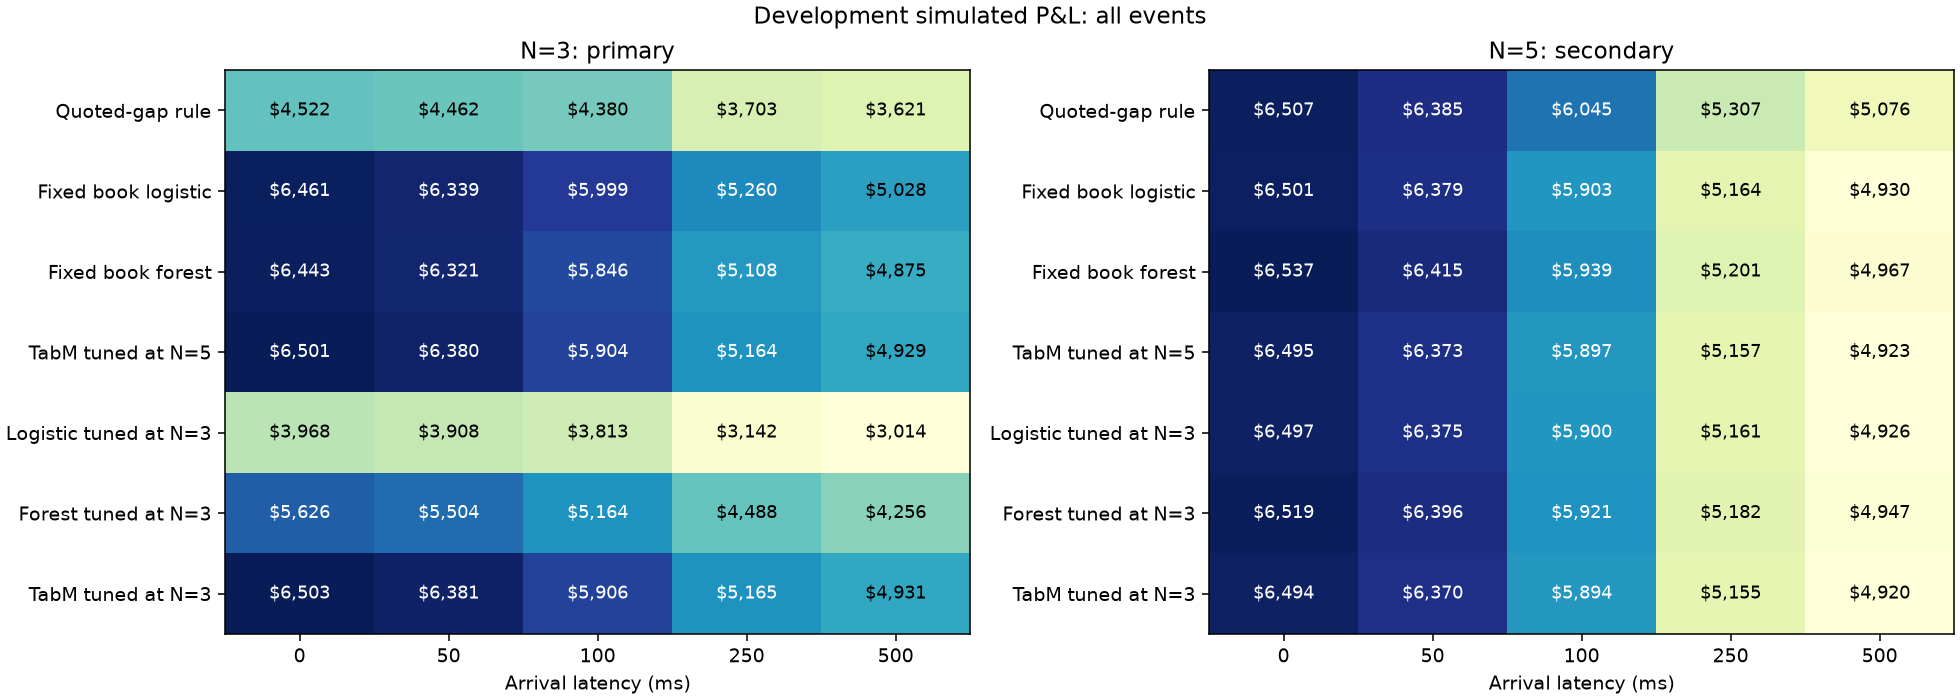

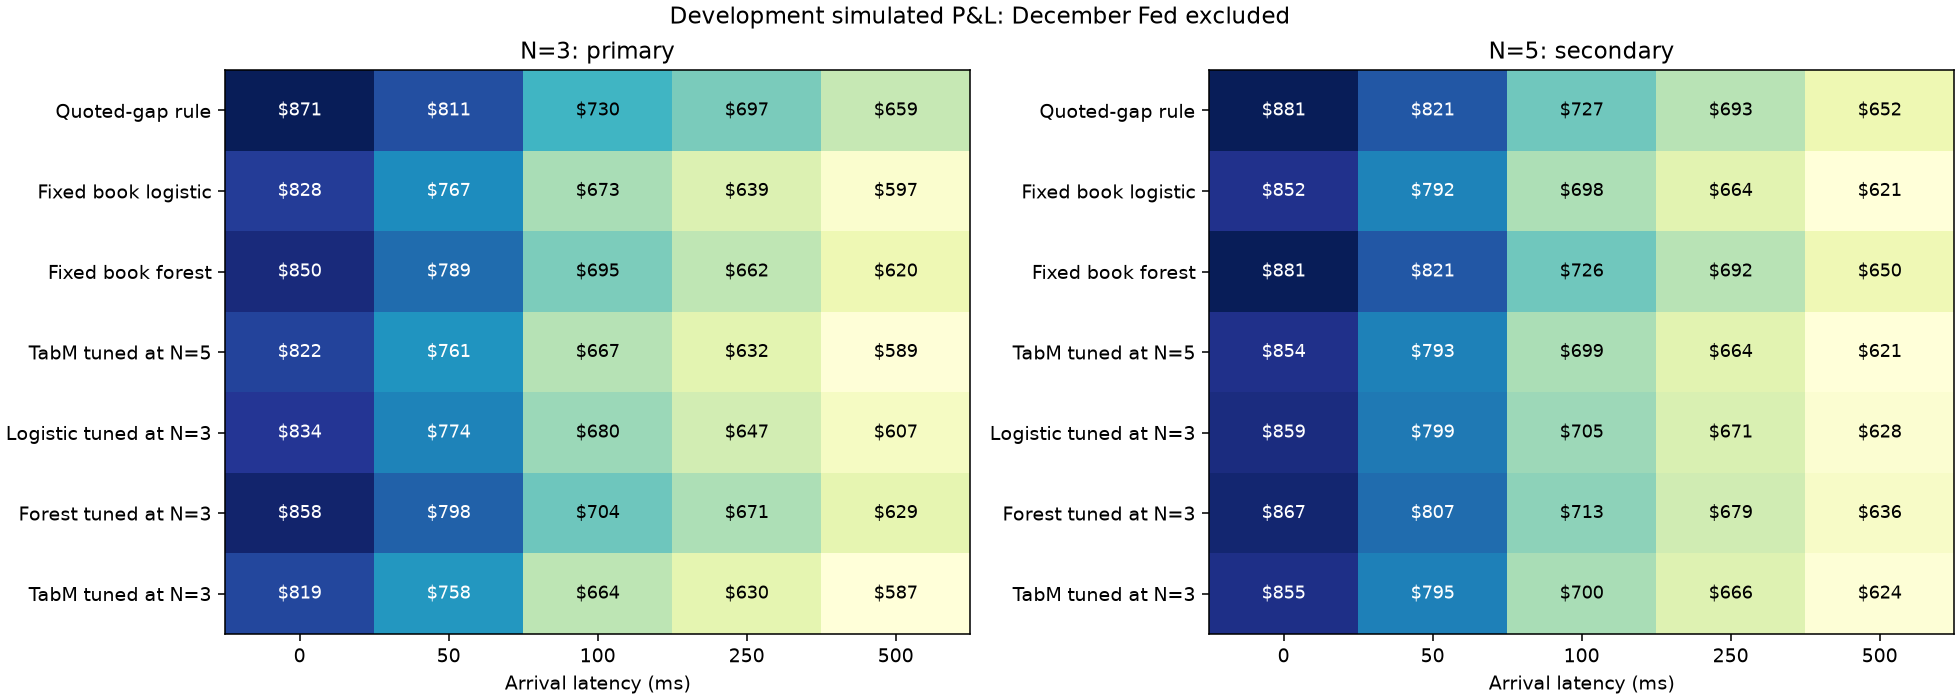

,scope,top_n,arrival_delay_s,model,difference_usd,lower95,upper95,families
0,all_events,3,0.1,n3_book_logistic,-566.61,-1613.36,-6.68,9
1,all_events,3,0.1,n3_book_random_forest,784.54,-101.01,2456.82,9
2,all_events,3,0.1,n3_tabm_two_stage,1525.86,-133.83,4695.55,9
15,all_events,5,0.1,n3_book_logistic,-145.31,-384.58,13.52,9
16,all_events,5,0.1,n3_book_random_forest,-124.27,-395.98,25.33,9
17,all_events,5,0.1,n3_tabm_two_stage,-151.19,-378.86,-1.89,9
30,exclude_december_fed,3,0.1,n3_book_logistic,-49.65,-120.55,0.79,9
31,exclude_december_fed,3,0.1,n3_book_random_forest,-25.98,-66.40,4.88,9
32,exclude_december_fed,3,0.1,n3_tabm_two_stage,-65.81,-145.05,-4.08,9
45,exclude_december_fed,5,0.1,n3_book_logistic,-21.89,-60.00,-0.04,9


In [4]:
economic = pd.read_csv(MODELS / 'analysis/economic_comparison.csv')
primary = economic.loc[economic.fold.eq('all') & economic.arrival_delay_s.eq(.1)]
columns = ['scope','model','top_n','known_pnl_usd','attempts','completed','partial_attempts','partial_pnl_usd','max_drawdown_usd','no_settlement_funding_usd']
display(primary[columns].sort_values(['scope','top_n','model']).round(2))
display(Image(filename=str(MODELS / 'analysis/all_events_latency.png')))
display(Image(filename=str(MODELS / 'analysis/exclude_december_fed_latency.png')))
intervals = pd.read_csv(MODELS / 'analysis/paired_pnl_intervals.csv')
display(intervals.loc[intervals.arrival_delay_s.eq(.1)].round(2))

## Final models: fitted, not tested

The full-development models are distinct from the earlier fold models. Their serialization probe uses earlier features only to check reproducibility; it is not an accuracy or profit assessment. The final test remains unopened. The final-test coverage/end-date audit and evaluation runner are still separate work.

Final gates and classifiers use 21,827 known examples; conditional amount models use the 454 positives. The final tuned forest selects the same settings as its fixed control and shares that fitted artifact. Other final configurations need not match the last development fold because the final fitting origin has more permitted history.

In [5]:
bundle = json.loads((MODELS / 'final_refit_bundle.json').read_text())
print('All training label windows finish before:', bundle['trained_before'])
display(pd.read_csv(MODELS / 'analysis/final_fit_inventory.csv')[['task','candidate','seed','training_rows','training_positive','label_end_last','epochs','artifact']])
display(pd.DataFrame([{'policy':name,'kind':entry['kind'],'raw_features':len(entry['features'])} for name,entry in bundle['policies'].items()]))
print('Final model bundle:', MODELS / 'final_refit_bundle.json')
print('No final-test scores, labels or returns have been inspected.')

All training label windows finish before: 2026-01-08 00:00:00+00:00


,task,candidate,seed,training_rows,training_positive,label_end_last,epochs,artifact
0,logistic,0,20261001,21827,454,2026-01-07 23:00:00+00:00,NaN,final_models/final_refit_logistic_c0_s20261001...
1,logistic,6,20261001,21827,454,2026-01-07 23:00:00+00:00,NaN,final_models/final_refit_logistic_c6_s20261001...
2,random_forest,0,20261001,21827,454,2026-01-07 23:00:00+00:00,NaN,final_models/final_refit_random_forest_c0_s202...
3,tabm_classifier,1,20261001,21827,454,2026-01-07 23:00:00+00:00,50.0,final_models/final_refit_tabm_classifier_c1_s2...
4,tabm_amount,1,20261001,454,454,2026-01-02 23:00:00+00:00,4.0,final_models/final_refit_tabm_amount_c1_s20261...
5,tabm_classifier,1,20261002,21827,454,2026-01-07 23:00:00+00:00,50.0,final_models/final_refit_tabm_classifier_c1_s2...
6,tabm_amount,1,20261002,454,454,2026-01-02 23:00:00+00:00,4.0,final_models/final_refit_tabm_amount_c1_s20261...
7,tabm_classifier,1,20261003,21827,454,2026-01-07 23:00:00+00:00,50.0,final_models/final_refit_tabm_classifier_c1_s2...
8,tabm_amount,1,20261003,454,454,2026-01-02 23:00:00+00:00,4.0,final_models/final_refit_tabm_amount_c1_s20261...


,policy,kind,raw_features
0,quoted_gap_rule,rule,1
1,fixed_book_logistic,classifier,33
2,n3_book_logistic,classifier,33
3,fixed_book_random_forest,classifier,33
4,n3_book_random_forest,classifier,33
5,n3_tabm_two_stage,hurdle_ensemble,36


Final model bundle: C:\Users\Daron\coding\inefficiency-prediction\results\final_preparation\final_refit_bundle.json
No final-test scores, labels or returns have been inspected.


## Using the prepared models on another platform

Construct the same as-of event features from that platform's raw books and metadata. Supply the full eligible pool for each scan, with `event_slug`, UTC `time`, the 33 book/history columns and the three metadata columns. Future labels are not required. Preserve the whole run folder so bundle paths and model hashes remain valid.

```python
# supplied_features must describe snapshots at/after the bundle's training cutoff.
# This example is intentionally not executed against the repository final test.
selected_events = predict_final(MODELS, supplied_features, top_n=3)
```

The helper returns selections for all frozen fitted policies and the quoted-gap rule. It performs feature-based inference only; the data pipeline and execution scheduler remain separate. Random and monitor-all references are retained in the planned final evaluation specification.